In [1]:
import warnings 
warnings.filterwarnings('ignore')

import pandas as pd 
pd.set_option('display.max_columns', None)

import numpy as np

import seaborn as sns
sns.set_style("darkgrid")
import matplotlib.pyplot as plt

import optuna
import lightgbm as lgb
import shap
from sklearn.metrics import mean_absolute_percentage_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_val_score

## Data Cleaning 

Carregar arquivo com os microdados

In [2]:
df = pd.read_parquet('C:\\Users\\pamst\\OneDrive\\Documents\\Projects\\Bases\\MICRODADOS_ENEM_2023.parquet')
df.shape

(3933955, 37)

In [3]:
df.head()

,NU_INSCRICAO,TP_FAIXA_ETARIA,TP_SEXO,TP_ESTADO_CIVIL,TP_COR_RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,TP_ANO_CONCLUIU,NO_MUNICIPIO_PROVA,SG_UF_PROVA,NU_NOTA_CN,NU_NOTA_CH,NU_NOTA_LC,NU_NOTA_MT,TP_LINGUA,NU_NOTA_REDACAO,"Até que série seu pai, ou o homem responsável por você, estudou?","Até que série sua mãe, ou a mulher responsável por você, estudou?","Incluindo você, quantas pessoas moram atualmente em sua residência?",RENDA,Em sua residência trabalha empregado(a) doméstico(a)?,Q008,Q009,Na sua residência tem carro?,Q011,Q012,Na sua residência tem freezer (independente ou segunda porta da geladeira)?,Na sua residência tem máquina de lavar roupa? (o tanquinho NÃO deve ser considerado),Na sua residência tem máquina de secar roupa (independente ou em conjunto com a máquina de lavar roupa)?,Na sua residência tem forno micro-ondas?,Na sua residência tem máquina de lavar louça?,Na sua residência tem aspirador de pó?,Na sua residência tem televisão em cores?,Na sua residência tem telefone celular?,Na sua residência tem telefone fixo?,Na sua residência tem computador?,Na sua residência tem acesso à Internet?
0,210059085136,14,M,2,Branca,1,1,17,Brasília,DF,NaN,NaN,NaN,NaN,0,NaN,A,F,5,5,C,C,D,C,D,C,B,B,D,C,C,B,B,B,A,A,B
1,210059527735,12,M,2,Branca,0,1,16,Brasília,DF,NaN,NaN,NaN,NaN,0,NaN,F,E,3,7,A,B,C,C,A,B,B,B,A,B,A,B,B,C,A,D,B
2,210061103945,6,F,1,Branca,1,1,0,Caxias do Sul,RS,502.0,498.9,475.6,363.2,1,700.0,H,E,5,2,A,B,D,B,A,B,A,B,A,B,A,A,B,A,A,A,B
3,210060214087,2,F,1,Parda,1,2,0,Fortaleza,CE,459.0,508.5,507.2,466.7,0,880.0,D,D,5,2,A,B,B,A,A,B,A,A,A,A,A,A,B,D,A,A,B
4,210059980948,3,F,1,Parda,1,2,0,Quixadá,CE,402.5,379.2,446.9,338.3,0,560.0,B,B,4,1,A,B,A,A,A,B,A,A,A,A,A,A,B,B,A,A,A


## Análise exploratória inicial

In [4]:
notas = ['NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'NU_NOTA_REDACAO']

df[notas].describe().round(2)

,NU_NOTA_CN,NU_NOTA_CH,NU_NOTA_LC,NU_NOTA_MT,NU_NOTA_REDACAO
count,2692427.00,2822643.00,2822643.00,2692427.00,2822643.00
mean,495.75,523.35,518.15,533.84,617.80
std,87.93,88.57,75.45,131.65,214.62
min,0.00,0.00,0.00,0.00,0.00
25%,440.50,467.80,471.40,431.20,500.00
50%,493.90,530.40,523.10,523.60,620.00
75%,551.20,584.90,570.30,630.10,780.00
max,868.40,823.00,820.80,958.60,1000.00


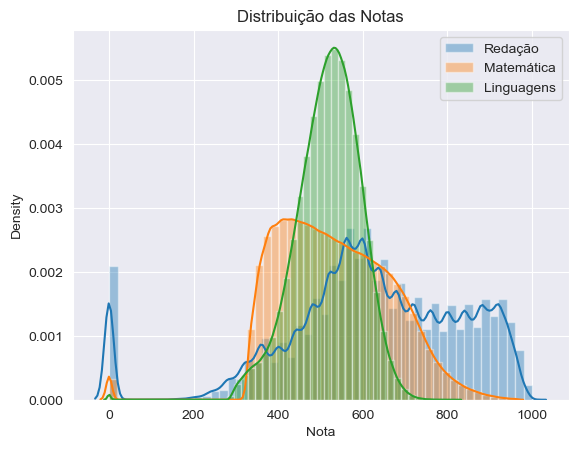

In [5]:
subjects = {'NU_NOTA_REDACAO': 'Redação',
            'NU_NOTA_MT': 'Matemática',
            'NU_NOTA_LC': 'Linguagens'}

fig, ax = plt.subplots()
for col, label in subjects.items():
    sns.distplot(df[col], label=label, ax=ax)
ax.set(title='Distribuição das Notas', xlabel='Nota')
ax.legend()
plt.show()

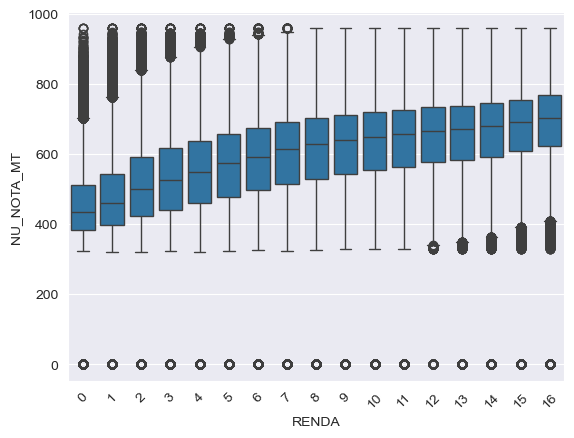

In [7]:
p = sns.boxplot(data = df, x = 'RENDA', y = 'NU_NOTA_MT')
plt.xticks(rotation = 45)
plt.show()

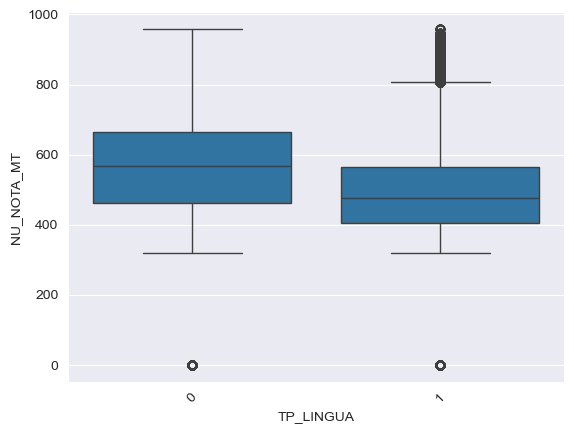

In [25]:
p = sns.boxplot(data = df, x = 'TP_LINGUA', y = 'NU_NOTA_MT')
plt.xticks(rotation = 45)
plt.show()

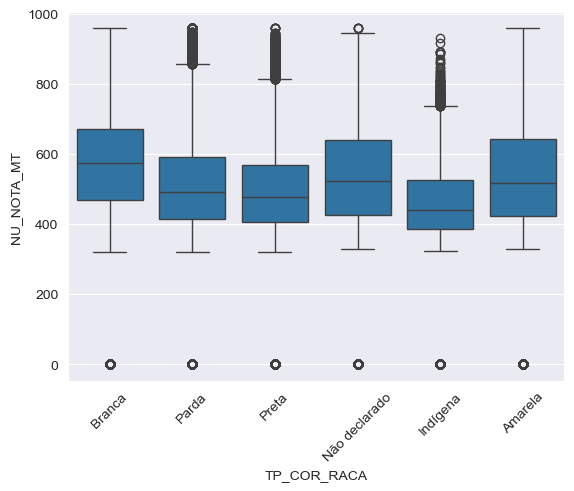

In [6]:
p = sns.boxplot(data = df, x = 'TP_COR_RACA', y = 'NU_NOTA_MT')
plt.xticks(rotation = 45)
plt.show()

In [11]:
df.groupby('TP_COR_RACA').agg(ALTA_RENDA = ('RENDA', lambda x: x[df['RENDA'] >= 15].shape[0]/x.shape[0]))

,ALTA_RENDA
TP_COR_RACA,
Amarela,0.028305
Branca,0.045593
Indígena,0.003723
Não declarado,0.022615
Parda,0.007468
Preta,0.003717


In [13]:
######TP_LINGUA 1 é a escolha da prova de espanhol
pd.crosstab(index = df['RENDA'], columns = df['TP_LINGUA'], normalize = 'index')

TP_LINGUA,0,1
RENDA,,
0,0.377328,0.622672
1,0.415416,0.584584
2,0.494219,0.505781
3,0.552004,0.447996
4,0.604043,0.395957
5,0.642275,0.357725
6,0.685547,0.314453
7,0.729895,0.270105
8,0.751623,0.248377


Analisando pelo recorte de gênero

In [15]:
df[['TP_SEXO']].value_counts(normalize = True)

TP_SEXO
F          0.612916
M          0.387084
Name: proportion, dtype: float64

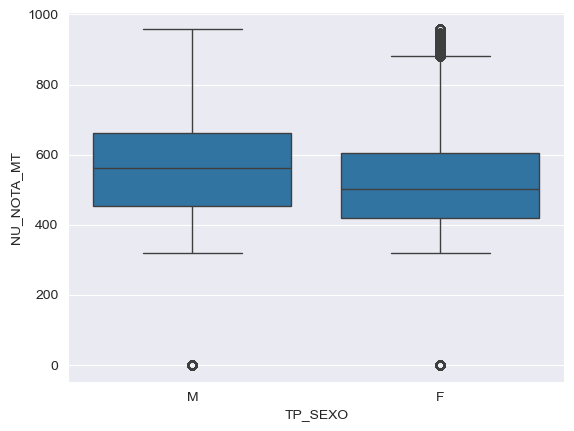

In [16]:
p = sns.boxplot(data = df, x = 'TP_SEXO', y = 'NU_NOTA_MT')
plt.show()

## Pré processamento dos dados

In [6]:
for col in list(df.select_dtypes(include = 'object').columns):
    df[col] = df[col].astype('category')

In [7]:
###Tirar quem nao fez a prova
df = df[df['NU_NOTA_MT'] > 0].reset_index(drop = True)
df.shape

(2675789, 37)

In [8]:
##########Trabalhar com uma amostra aleatoria
df_modelo = df.sample(500_000, random_state = 42, ignore_index=True)

In [9]:
########Ajustar o nome das colunas
df_modelo.columns = df_modelo.columns.str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8').str.replace(r'\W+', '_', regex=True)

In [10]:
#########Criar uma amostra aleatoria para a validação do modelo
np.random.seed(42)
df_modelo['AMOSTRA'] = np.random.choice(['DEV', 'OOS'], size = len(df_modelo), p = [0.7, 0.3])

In [13]:
df_modelo.columns

Index(['NU_INSCRICAO', 'TP_FAIXA_ETARIA', 'TP_SEXO', 'TP_ESTADO_CIVIL',
       'TP_COR_RACA', 'TP_NACIONALIDADE', 'TP_ST_CONCLUSAO', 'TP_ANO_CONCLUIU',
       'NO_MUNICIPIO_PROVA', 'SG_UF_PROVA', 'NU_NOTA_CN', 'NU_NOTA_CH',
       'NU_NOTA_LC', 'NU_NOTA_MT', 'TP_LINGUA', 'NU_NOTA_REDACAO',
       'Ate_que_serie_seu_pai_ou_o_homem_responsavel_por_voce_estudou_',
       'Ate_que_serie_sua_mae_ou_a_mulher_responsavel_por_voce_estudou_',
       'Incluindo_voce_quantas_pessoas_moram_atualmente_em_sua_residencia_',
       'RENDA', 'Em_sua_residencia_trabalha_empregado_a_domestico_a_', 'Q008',
       'Q009', 'Na_sua_residencia_tem_carro_', 'Q011', 'Q012',
       'Na_sua_residencia_tem_freezer_independente_ou_segunda_porta_da_geladeira_',
       'Na_sua_residencia_tem_maquina_de_lavar_roupa_o_tanquinho_NAO_deve_ser_considerado_',
       'Na_sua_residencia_tem_maquina_de_secar_roupa_independente_ou_em_conjunto_com_a_maquina_de_lavar_roupa_',
       'Na_sua_residencia_tem_forno_micro_ondas_',
  

### Tunning Modelo

In [40]:
def tune_prova(dataframe = pd.DataFrame(), target = ''):
    """
    Funcao faz calibragem do modelo 
        - Args: dataframe (dataframe completo), y (var dependente)
        - Return: dict com melhores parametros 
    """
    
    variaveis = ['TP_FAIXA_ETARIA', 'TP_SEXO', 'TP_ESTADO_CIVIL',
       'TP_COR_RACA', 'TP_NACIONALIDADE', 'TP_ST_CONCLUSAO', 'TP_ANO_CONCLUIU',
       'NO_MUNICIPIO_PROVA', 'SG_UF_PROVA', 'TP_LINGUA',
       'Ate_que_serie_seu_pai_ou_o_homem_responsavel_por_voce_estudou_',
       'Ate_que_serie_sua_mae_ou_a_mulher_responsavel_por_voce_estudou_',
       'Incluindo_voce_quantas_pessoas_moram_atualmente_em_sua_residencia_',
       'RENDA', 'Em_sua_residencia_trabalha_empregado_a_domestico_a_', 'Na_sua_residencia_tem_carro_',
       'Na_sua_residencia_tem_freezer_independente_ou_segunda_porta_da_geladeira_',
       'Na_sua_residencia_tem_maquina_de_lavar_roupa_o_tanquinho_NAO_deve_ser_considerado_',
       'Na_sua_residencia_tem_maquina_de_secar_roupa_independente_ou_em_conjunto_com_a_maquina_de_lavar_roupa_',
       'Na_sua_residencia_tem_forno_micro_ondas_',
       'Na_sua_residencia_tem_maquina_de_lavar_louca_',
       'Na_sua_residencia_tem_aspirador_de_po_',
       'Na_sua_residencia_tem_televisao_em_cores_',
       'Na_sua_residencia_tem_telefone_celular_',
       'Na_sua_residencia_tem_telefone_fixo_',
       'Na_sua_residencia_tem_computador_',
       'Na_sua_residencia_tem_acesso_a_Internet_']
    
    train_x, test_x, train_y, test_y = train_test_split(dataframe[variaveis], dataframe[target], test_size = 0.3)
    
    def objective(trial):
        """
        Cria o Trial da funcao 
        
        """
    
        params = {
            'objective': 'regression',
            'metric': 'mae', #usando MAE como métrica 
            'boosting_type': 'gbdt',
            
            'num_leaves': trial.suggest_int('num_leaves', 31, 255),
            'max_depth': trial.suggest_int('max_depth', -1, 16),   
            'min_child_samples': trial.suggest_int('min_child_samples', 20, 150), 
            'learning_rate': trial.suggest_loguniform('learning_rate', 0.005, 0.1),
            'feature_fraction': trial.suggest_uniform('feature_fraction', 0.6, 1.0),
            'bagging_fraction': trial.suggest_uniform('bagging_fraction', 0.6, 1.0),
            'bagging_freq': trial.suggest_int('bagging_freq', 1, 7), 
            'lambda_l1': trial.suggest_loguniform('lambda_l1', 1e-6, 10.0),
            'lambda_l2': trial.suggest_loguniform('lambda_l2', 1e-6, 10.0),
            
            'seed': 42, 
            'n_jobs': -1, ##use all GPUs 
        }

        # Train and evaluate model
        model = lgb.train(params, lgb.Dataset(train_x, label=train_y), num_boost_round=1000,
                          valid_sets=[lgb.Dataset(test_x, label=test_y)], early_stopping_rounds=50,
                          verbose_eval=False)

        y_pred = model.predict(test_x)
        mae = mean_absolute_error(test_y, y_pred)
        return mae

    # Create Optuna study and run optimization
    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=25)

    # Print best parameters and MAE
    print('Best parameters:', study.best_params)
    print('Best MAE:', study.best_value)
    return study.best_params #retorna um dict com os melhores parâmetros encontrados. 

In [41]:
# params_mt = tune_prova(df_modelo.query('AMOSTRA == "DEV"'), 'NU_NOTA_MT')
# locals().update(params_mt)

[I 2025-08-11 21:55:26,092] A new study created in memory with name: no-name-8bb21ceb-d187-4a03-a9b1-d72e24651fe6


[LightGBM] [Warning] Auto-choosing row-wise multi-threading, the overhead of testing was 0.013018 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1759
[LightGBM] [Info] Number of data points in the train set: 245036, number of used features: 31
[LightGBM] [Info] Start training from score 534.043148


[I 2025-08-11 21:55:52,246] Trial 0 finished with value: 83.47538825660698 and parameters: {'num_leaves': 42, 'max_depth': 16, 'min_child_samples': 139, 'learning_rate': 0.01585850349687891, 'feature_fraction': 0.6114155043183416, 'bagging_fraction': 0.6322840856779285, 'bagging_freq': 2, 'lambda_l1': 0.056395455010079226, 'lambda_l2': 7.958931923529117e-06}. Best is trial 0 with value: 83.47538825660698.


[LightGBM] [Warning] Auto-choosing row-wise multi-threading, the overhead of testing was 0.018126 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1759
[LightGBM] [Info] Number of data points in the train set: 245036, number of used features: 31
[LightGBM] [Info] Start training from score 534.043148
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best

[I 2025-08-11 21:56:04,997] Trial 1 finished with value: 83.52087622268014 and parameters: {'num_leaves': 93, 'max_depth': 5, 'min_child_samples': 43, 'learning_rate': 0.061353113912813666, 'feature_fraction': 0.7615701893610415, 'bagging_fraction': 0.9016581388605303, 'bagging_freq': 7, 'lambda_l1': 0.27529645314795287, 'lambda_l2': 1.4123157882955894e-06}. Best is trial 0 with value: 83.47538825660698.


[LightGBM] [Warning] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014223 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1759
[LightGBM] [Info] Number of data points in the train set: 245036, number of used features: 31
[LightGBM] [Info] Start training from score 534.043148


... (42 outputs left out)

[I 2025-08-11 22:04:13,808] Trial 23 finished with value: 83.3037053127863 and parameters: {'num_leaves': 190, 'max_depth': 12, 'min_child_samples': 119, 'learning_rate': 0.01902621031423556, 'feature_fraction': 0.661348219484347, 'bagging_fraction': 0.6452004839614676, 'bagging_freq': 2, 'lambda_l1': 0.0011468511159444935, 'lambda_l2': 6.5832469086447854e-06}. Best is trial 23 with value: 83.3037053127863.


[LightGBM] [Warning] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017349 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1759
[LightGBM] [Info] Number of data points in the train set: 245036, number of used features: 31
[LightGBM] [Info] Start training from score 534.043148
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best

[I 2025-08-11 22:04:50,409] Trial 24 finished with value: 83.28228290956916 and parameters: {'num_leaves': 195, 'max_depth': 13, 'min_child_samples': 150, 'learning_rate': 0.018533123578477816, 'feature_fraction': 0.6508036201026256, 'bagging_fraction': 0.6610936897466139, 'bagging_freq': 3, 'lambda_l1': 0.0017153326725490956, 'lambda_l2': 5.122057119620838e-06}. Best is trial 24 with value: 83.28228290956916.


Best parameters: {'num_leaves': 195, 'max_depth': 13, 'min_child_samples': 150, 'learning_rate': 0.018533123578477816, 'feature_fraction': 0.6508036201026256, 'bagging_fraction': 0.6610936897466139, 'bagging_freq': 3, 'lambda_l1': 0.0017153326725490956, 'lambda_l2': 5.122057119620838e-06}
Best MAE: 83.28228290956916


In [11]:
params_mt = {'num_leaves': 195, 'max_depth': 13, 'min_child_samples': 150, 'learning_rate': 0.018533123578477816, 'feature_fraction': 0.6508036201026256, 'bagging_fraction': 0.6610936897466139, 'bagging_freq': 3, 'lambda_l1': 0.0017153326725490956, 'lambda_l2': 5.122057119620838e-06}
# locals().update(params_mt)

treinando o modelo

In [12]:
variaveis = ['TP_FAIXA_ETARIA', 'TP_SEXO', 'TP_ESTADO_CIVIL',
       'TP_COR_RACA', 'TP_NACIONALIDADE', 'TP_ST_CONCLUSAO', 'TP_ANO_CONCLUIU',
       'NO_MUNICIPIO_PROVA', 'SG_UF_PROVA', 'TP_LINGUA',
       'Ate_que_serie_seu_pai_ou_o_homem_responsavel_por_voce_estudou_',
       'Ate_que_serie_sua_mae_ou_a_mulher_responsavel_por_voce_estudou_',
       'Incluindo_voce_quantas_pessoas_moram_atualmente_em_sua_residencia_',
       'RENDA', 'Em_sua_residencia_trabalha_empregado_a_domestico_a_', 'Na_sua_residencia_tem_carro_',
       'Na_sua_residencia_tem_freezer_independente_ou_segunda_porta_da_geladeira_',
       'Na_sua_residencia_tem_maquina_de_lavar_roupa_o_tanquinho_NAO_deve_ser_considerado_',
       'Na_sua_residencia_tem_maquina_de_secar_roupa_independente_ou_em_conjunto_com_a_maquina_de_lavar_roupa_',
       'Na_sua_residencia_tem_forno_micro_ondas_',
       'Na_sua_residencia_tem_maquina_de_lavar_louca_',
       'Na_sua_residencia_tem_aspirador_de_po_',
       'Na_sua_residencia_tem_televisao_em_cores_',
       'Na_sua_residencia_tem_telefone_celular_',
       'Na_sua_residencia_tem_telefone_fixo_',
       'Na_sua_residencia_tem_computador_',
       'Na_sua_residencia_tem_acesso_a_Internet_']

model = lgb.LGBMRegressor(**params_mt,objective='regression', random_state=42)
model = model.fit(df_modelo.query('AMOSTRA == "DEV"')[variaveis],
                  df_modelo.query('AMOSTRA == "DEV"')['NU_NOTA_MT'])

[LightGBM] [Warning] feature_fraction is set=0.6508036201026256, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.6508036201026256
[LightGBM] [Warning] bagging_fraction is set=0.6610936897466139, subsample=1.0 will be ignored. Current value: bagging_fraction=0.6610936897466139
[LightGBM] [Warning] lambda_l1 is set=0.0017153326725490956, reg_alpha=0.0 will be ignored. Current value: lambda_l1=0.0017153326725490956
[LightGBM] [Warning] lambda_l2 is set=5.122057119620838e-06, reg_lambda=0.0 will be ignored. Current value: lambda_l2=5.122057119620838e-06
[LightGBM] [Warning] bagging_freq is set=3, subsample_freq=0 will be ignored. Current value: bagging_freq=3


In [13]:
y_pred_dev = model.predict(df_modelo.query('AMOSTRA == "DEV"')[variaveis])
y_pred_oos = model.predict(df_modelo.query('AMOSTRA == "OOS"')[variaveis])

mae_dev = mean_absolute_error(df_modelo.query('AMOSTRA == "DEV"')['NU_NOTA_MT'], y_pred_dev)
mae_oos = mean_absolute_error(df_modelo.query('AMOSTRA == "OOS"')['NU_NOTA_MT'], y_pred_oos)

mae_dev, mae_oos

(82.37810367579816, 83.64264515174573)

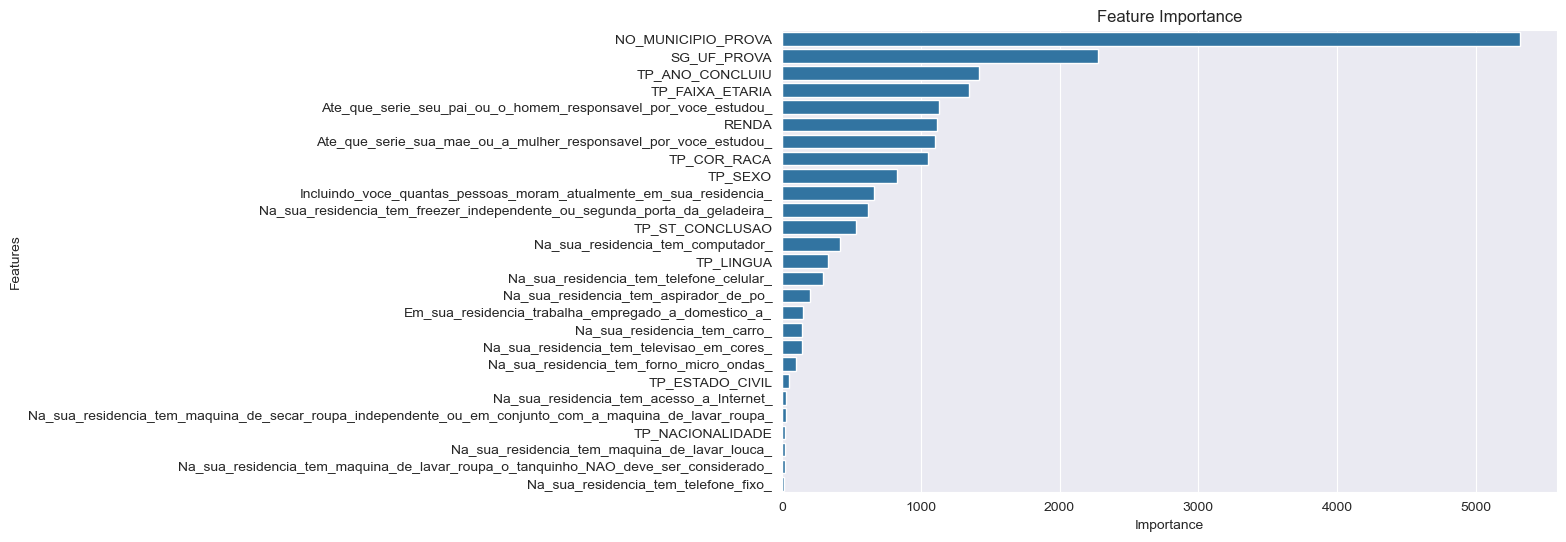

In [14]:
#Construir o feature importance
feat_imp = pd.DataFrame({'Feature': variaveis, 'importance': model.feature_importances_})
feat_imp = feat_imp.sort_values(by = 'importance', ascending = False)

#plot
plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='Feature', data=feat_imp, orient='h')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.title('Feature Importance')
plt.show()

proximos passos 
- Clusterização
- Meta modelos para criar um modelo stacking e melhorar performance